# MIT 6.4610: Post-hoc evaluation with the three-example prompt (copy of Sophie's section 8)

This is a **copy** of `4610_crosslingual_extended.ipynb`; the original is unchanged. It reruns Sophie's post-hoc evaluation (section 8) on Rohan's saved checkpoints A/B/C. **No training.** Only the evaluation prompt is different.

**What changed from the original:**
1. **Prompt.** Every question is preceded by three worked examples in the test language, about made-up entities not in the dataset, with that language's own labels:

   | Language | Labels |
   |---|---|
   | French | `Question : … / Réponse :` |
   | Finnish | `Kysymys: … / Vastaus:` |
   | Chinese | `问题：… / 答案：` |

   These are the same prompts as `results/rohan_fewshot` in the shared `xling` pipeline. With the bare `Q: …\nA:` prompt, base Qwen tends to answer in full sentences, so the single-word answers get very little probability.
2. **Answer spacing.** Chinese answers follow `答案：` with no leading space; other languages keep `' ' + answer`, as before.
3. **Two positions.** Hidden states are taken at the last prompt token (as before) **and** at the last token of the entity's name in the test question (new; `position = "subject"`). One forward pass gives both.
4. **Strict transfer table.** It also reports each language's own denominator: the facts where checkpoint B preferred the original answer in that language. It also reports the base rate at A.
5. **Figures.** The accuracy bar chart is replaced by an old-vs-new preference plot per checkpoint. The original chart scored A/B against the old answer and C against the new one, so the bars weren't comparable.

**To run:** use a GPU runtime and run all cells. The setup cells below are copied unchanged; the training cells are left out. Results go to `64610/results/alignment_fewshot` on Owen's Drive, or `4610_crosslingual_results_fewshot` on Sophie's.

In [5]:
%pip uninstall -y transformers peft

%pip install --no-cache-dir \
    "transformers==4.57.6" \
    "peft==0.18.0" \
    "huggingface-hub>=0.34,<1.0" \
    "accelerate>=1.5,<2" \
    "datasets>=3,<5" \
    sentencepiece safetensors pandas

Found existing installation: transformers 4.57.6
Uninstalling transformers-4.57.6:
  Successfully uninstalled transformers-4.57.6
Found existing installation: peft 0.18.0
Uninstalling peft-0.18.0:
  Successfully uninstalled peft-0.18.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 188.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 556.4/556.4 kB 575.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [peft]


In [6]:
import os, json, base64, zlib, random, gc, math
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM,
                          TrainingArguments, Trainer, DataCollatorForLanguageModeling)
from peft import LoraConfig, get_peft_model

assert torch.cuda.is_available(), "Select Runtime > Change runtime type > GPU (A100 if available)."
print("GPU:", torch.cuda.get_device_name(0))
print("BF16:", torch.cuda.is_bf16_supported())
SEED=4610
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

MODEL_ID="Qwen/Qwen3-1.7B-Base"
OUTPUT_DIR="/content/4610_pilot_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)
LANGUAGES=['en','fr','zh','fi']
EPOCHS_ROUND1=3
EPOCHS_ROUND2=3
LR=2e-4
BATCH_SIZE=2
GRAD_ACCUM=4 # effective batch size = 8
MAX_LENGTH=128
# For an 8-10-fact smoke test, uncomment the next line; then reset to None for the full pilot.
ACTIVE_IDS=None
# ACTIVE_IDS=[1,2,5,6,10,13,17,18,24,31]

GPU: NVIDIA L4
BF16: True


In [7]:
DATA_B64 = '''eNrNfWuTFEeS4F9JYz6wa0Zr9UDa250PZ4BecyckrdCNbO/sDIuuiqoKKiujJiOzmtLYmKEZSYiXhN5ogEVIjaD1GkAM4ik+1D8566ru/jR/4d
w9IjMj31lNIzAbDdVVEf6KCA8Pdw+PP25rs4ApHuz32IBv+3dn2z7+h5B7gWCu0xGtQEgPPvU9ueTydpc74RA68H93fD4SfIm3nZ1PLYiAD5yh
cGWwbYezbcR9Bb0Q1jOPPblA3y88+fiTzyw88cTCE89gE+ywvyVDL4BWO5+Cb1zmdUPW5Qq++D/buIetOj7+/5s9+iy2/V/4J/CZ8ITX3e9D5z
Y2/uM2+rj/CcT3ii+6wktR3mGtQCEE3exJbLZHeh0XW3hdqyXRw33d4U/Qg4+YGzL8db8fuiSc13vc4QeHvBUA58xTS9x3hHLa3Bcj+IYfbLmh
go/u2On4cuAYpI85z7FWzwm4ChyQrkKYTqi4cpQYDF2+w2kLH4A6S9JvA1U7HBwN5QSAzucuEOIFFqU4PMHYabmc+e54BxACxKi+cjrSpz56kN
rEvLMkgp4MA0cFjDiGNj4fcv0HttZ8PObson8VEuYwEIfXEvCpxTzpiRagdflB+hewDH7rDH05BO41oT4PYGAImoIvHDXkrovwWcuXSjnx8D7m
vBwOQFotg1U5zOfOki+CgHvAhOOFg0UAi4JQj0VzhWbFH7eJNvz7BI4MCQAH5CWCxrbFX+4PxkMaqlhc+wdSeskMeIJmGA4kfg/SWBQkCQPJYU
OQDdC16IacCDA/bFe6Qw+IZPSro0KcLboVAnRDj/nRt47sxDCFBS7BnPq9JV3pw5DF7XYjBqHnQASSGlkdDU2P0dpIJngT9ro+5145f/TzXAwm
AGs4TBq+QEjm4RFXkF713KN/otWEI/5GjwWmewZmDtp/R/R6BmJPIonWfMfPgX2W45p1XSQN1EDoO7iMXRZDb3P8C2RDHyOOMyhAKwacUIBCy6
KI+qz99e3pie9mp86tn7+0cfar2am/rd4+tHrzvY2vzqwfufqPO+fSMNdu34OvNd0iB3Sv8PqTZWc0WfaFB3KGATF4PKcfhh5obC9gWTJFz+eT
5W1/QqDSqNP9Zq0mgt+G03RbJC/4i+s/ibdt6x+fRboisrYp1NkoYABqVvGTqVX8svRHSNYrfqvH/LazR6JuAQ014pUrW/pd5ok3SUcXrfAKuD
AN5ZLC5eByrWh20UfSRzh3BqjQOn4oYE6FLnQhjbo4ph8rAMdLoAo56McW7LDiTUAIaIgK1KjtkFhL6CEycf2aGT2EsWyJIWhh1gUtCoSFPv4B
3Ua4J8BM3wr6AM2A+QK2sZj3RFZFyqZe0qR2CPmrpIAehpyRhqyYkZpHScpGTs20nZZbWxpboW4UMosdUZVpvf8AlZcaFlJyVQiywCWYNGUKrw
rO2sUTs+UTWvHNLl+b/deZnOKbfXWpXOsFoPR6vM3dwWQZPlahGgn3AJhXPEs6dvTHXgM9SGsiUYRDORjYivDYTSA/UYRywD1mq8GdKTX4ew57
F5D6EkzFUABLLed3HvwThEG1HvS5gqFs9fYLu3lWG1aBR3MPVwUskwDNOQ0P18y+IahY1aMJbT5HywSMtD6umsi6i9ZFFSKC85qBT/ZfUNuHLN
IIt7FxBdmI/SKyZAckg+eXmI25CdzlupYSiOE0oZUsHZIlqDFbfkVqc3ND8gL3B8yYUPTxoQyIQV0wHmmiHq3hiGTXTL/GlMYqtlYsKA97wDK6
ReOv0rou12jhnzp0gXDhiLYQLAiQjwTLVNFZDMcR/lNZlcwANiBvl2nlSmSrd++tfXJp+vG3oJ/X//bD+qVD6/dOr58/vvblJ2sr13MqevrLz9
CqWkv3BXfx30q8YMOOg4BUOfzdF4OwD1wqxrJGvGJ9xWoVtlmOicrmasi6nnQtrX3h3toHP6wd+QIZiHU3tvMOpLT30ynt/RwcsJGL1+QYJule
0PRdMLarFTfQMoB/4NDi8laZFRsvID4AQ3sQrZoSfIkucDuxFYJ/4KkfJ6UXqKr+esHpHtFhUXrpldyIkBh5GaHkAGEGk9ZyajxYlG5tz1ZPKh
5zGXXWVLGAnAso12KduzlxduTBmCz4PJ8wscOvIktCtElRWn1LJFmvL3VrlNmm2MysaKCo0jw12DqiG/p02Hfc7YhncmkQYYZWeDzfXsZ+BqMP
P/il+rEMCB7bfzw1++zm9Je7a999uXrjaHxynx69tHZkJX9yP3Zy7diNcu2IB3fuTpYFHdv7IRwNgrBMah7YsXA8wa0A9CJoSc8zOjLDXZ8DlF
oNiUsqUY+uDIeJalw7dsc61odK2OrwmZQ6fJW7bSDtlUXFfSBf+uNKTbgYChddn0UKsC1pPJ08SJxpA9amX1UgPb1Q9uGnaOHC7q8CXx/4oG2A
DhA3mocFEBFZvGoqMCNc2KtUGnVBQ+1QoyYJcE3iEiNva9sJZEInEVaOuFipNRNRS4IS8omAPfTx1xSShbxUSrpNAt5QuXk51assI4EKJoz0Mo
tJk1qmn57zIqchqtHJJdBP6DXsMDhPw5ftybUBeQsL0GXxhGJUfpAu6A/aaG3l5sb566CEwGIzB+mzJ2effTF97/rsvZPQIKeQNj4+U66NFBpp
ZlYwUDMBK6Ab1dRQuoI0P+8F46zyCYfMF7Xah9aJdaAW3PetE/XauZ+my9cSHdQXo5QO+teUDvrfQLFXqXaGYGoH+8lNxFWR7iEQDjVzFl0pB+
RIUnga6ZrDp295jjquXOL0BVj/SvvACQS11cB0G2UsAqcd6vYJyASvIcz4rDiGEaRSKSICYdaK7iFwGWlyA/IQGWQW0UX6o5hNFgbhwHgj6eP9
s2mBbMim1aOWxaht7dL/necs9QScIQ398fkuJ4jsGYowlC37yaFo2SsmEK5rKI0AdzCAIIIFapMHLQde6VLXAGbLJ8CgmJ7Bk9jqjW+nP3y9fv
TP0zuH1o9eyVsZF4/B7xXxAQwPhBIWMhN95jFN40KfqZGA1dzvC5E9Y437aly/hmmiWYsY/gz4YKiSdTw7dQFJS9YxH02WA3sl/7fUSn7FXxSq
diXzILuEqR9tLkHP59zxmHblKtBmYDEFxvf/Ov2IkSGlQ2baDUwgHYIRz1j7SzJ0sXnksY6hUHPdZghTmeP/cr8DONgXtCO8mDj4EZmJSMiu3I
S7DrozS5h7Hn+7X946MZBC1jI/J5yVEFbAWOV6fVEuwQ7kjYtAxWs3RX6PjXLnCYwnlazcPXKwiKZ0m9ugCRt3VbSOJ5dgJSe8Ty610ftStJhb
wvtD2UpeP398duqcgTM7c2S6/Nfp5Q83vvp8uryy9vZ1HQLMrebVW5+ULeX/GQqvz0D+XoCBSOl50tX7dD8MA0065wGcEZjBmguBjoRQ9bszzd
NkYQe+FNaiXr1xxFrR0h1we0H/W2pBPwtnYXTL7wWjALcw57mDQ+kHDozDEMa5cqm3kjbZ7boGrKN6YogewU4H1htb9CVrG0OTvsnFf7jubizh
GujxOqqjAmNe7tgAj8ih3nslWIkSU2hgXyJqB+RjaEZAZG9rczsGmmbO5QwPWlEczFCRxNxqmSyyH5rJPeDMFvrrnD0kiQMhWyhu3d6AtJjaEk
nXn2Ai8LEenEsYGT0AbFT6XAiZoPyHOjSG3UhBxkPMUcZZfRn0Jitl+rIO0eqN2+vfvDU9fGv6wdf6uLN66+L047dyKnT9+PVqj3QQyoAHQT1v
IwEMoVOaQbO8pyXgvFaX6gWaKNMW64AIYmU6/eiz6afnLX3KeumjzhOPpxTqbnKiV+rNjssK/SuLrNXv6v3YTPzdxiOPPXA2+1yvWP39dtoYTX
4dttCHd0pfikGZuFI7WgwWkjjFJ4sq8bAKOF+WERMlEkVE7cpgzrpaqR/A0nCK9Ve9CMYwieVSvRR0u6wg/lN/+8BkYVG3K09CE4nMmVqVFlgs
EYScWQuamjmzq9AdDaDbodP2GdAeomGmsWQ1xwEWlh+aTJfp6buzzz9HP+2tT9ePXI3ds3k/yO2350upigbEFcMQhMtCFeTdri5mR5oEqCqVAC
OZ6AMQbtf2fNz6KpVUBehYNqvqiXRyJM6eXX8IhQt0gv7ibRGFmEpVBE81yyqKPDCnLVQLN1DMh4UjNcOjb4+ZQPAu+xvy4sUZP1G/OJkmDzte
AfmftivLYkhALdEKzFJhB7fNAihgpKMXSgMeLJaNU6OM/iJNUydDOOXA/uOzscEe//2ryS9NwXzSq6Z+PsnVaySF9qQOArVFu4y2CGtmWcakNY
kxYZ4WLPLtBeBZZOC0JyugwzDRMxdWYoJrUZTpqQK40w8+XHv/8uqtd3XMffb3n2fXjpXEk9bPfrlx9U6N2sLcTwoqgf1VJCd3cn2sRJGUfFBr
/QaRo2ShWGqMAyZvYRF+Ep6lzzau3ti4einRZyPmMuiaMnGefiqlz94AlgboWHgVzHYYlD2AKeB+tVuImu73eTd0S/NESwA7RLvPVRLGdME6xJ
UQSGcRHfiu0NMZLPqehFPEAmxXS57Tgv60Av6X1+Y6J78Exw7c92BcAOYA9g5KIclC0on9WRq0Hyb6siV9IHQImyb3Whx9oTFC3LFhi1LJ4SOL
wAnryIx1Sa2oiomnEIuWFmmsmBlQZjpI/WKuH7qP4qgP86ljZhga0F2kg7dkvBdFa9xy+eaH2QDY8tE1cLdyUFOk1o/l7qj51g1hvXcwJL9HBn
pq0GpRZXRfIssKryEdZuE0XCZDflB04zPwHyirSxF5yTzDn5SjpCBQYuRPVvLJW5Mvwe5ccWXZDlKGf/3i29Mf/6rzE1bvnV+9fX16752N87en
3/x59e6ns6Ofbhz6KG8Gf/vh+uFv188fX7/7TcWJmXulbFPyrU9pW3F2QuD0hX+Aw7+BFANBJ+2R6Of2nKF0++FwPLkO/V23yW2EvEqzErzgCy
DKxxnhBAKF6wwxIAUyBrNmxMKDlgvz5qmNle+R63hjgiZSwf4Js1fE1EQG91M5g3svWPs9StN4EfbbAJMHX6FsvKDmdA4TWLT2c09RqkzRNlUF
2hlyHy9mkTbQGzquSIRJN8DgZBbGAQH6GGfgJ5ag3VVQmD3lDqvCH+uSaiJ9OcBDS4AX5Dg515WhDJUa5h4ZPhjouRS1+KXOVYDufopAzG0Ph4
65gHb/VFpiADqHLhsbIrU8i/eU+xoc6DjU3L6Inx6ZoSG6SkdG0/qQBwZJtMel5tQgKIU6JjD2mVbixd3aCCE3gBndheTU+Dps/G4N5gMyNPm9
bcDhKEZIcRuJCfGKwk9IRqlTpBLj7M4n0wsfrN75cu32uY1zP63ePDn7/Lqd/AvfTL+4lA82f/fZ2slr1e5V2OICvHRWzbOV8TvkFDqmzDY8wQ
Dvoi+Ksn+R4WH9EYWWcbI3dNzJ7cA+lHx6b+3705buh0NSmFL46Rsbz/uw62GkETdCBvPId/YFrNbLsqTb7ldB6ZGkHDImeEu/jdd7fc7fxFO0
ry/foseIrvpSZiwKTpt4z6fapdwIuhUsfg5qRmQRmDhFOS3xsm1C7hAvhqsAp32acrO0DC26vZoLdA6e1alcLjXQ27JFizQH3wiwSHbFe0MTFn
qcjcaO8uRSB7RbBdUvphs+CsOZof3+xzMPcIsHNIOgdkTrfVF9oV3hhUOA3qlavrMaLUVipZMKNQw6yIdg3CZYYW/Egw8oHE4JDBUExD4s7vm8
C6MKgJxcNrYfkMlM5hhg8zicbMr2mApk6z9ent79FJ3x734//eHrjS9O4DW/yCW/duX29L+O5e+TLF/cOP1t+fbiuowSHuAMMqIPirUpkldBCJ
5GWO704YeegvnghgOBMOq3FFs3WElPbii4A/LvumxyEVPArNjeu7c3Tlu+rwO42cGON8I9MsIZ7TjpWyZ7mNtGV+SuoAeHSLAfdykl4chbu+eQ
g0DVXpmugu+YzugQYKrPg0VcO5iNAS1pxunTf/JbLrqv7OB+Fa54PVcSlNygRfNVBinKdO5DVXcq3dEWLbpyjC6edN869FhMgFH6IjClq12YC8
IiTUfRntBQ0CO8GjQuFvTvk98egqATyuYXdKbvfQnahtXwAKCFE9v+jYYimy8VY63UzBoTKN8GOFRZLlkGV4G2rYS+dvvttduHjfF+9+P1P1+d
/e2T9b+fzl+rfv+jtZN/qYkihH6Pg1HssgMCNag7ZPDXgRoGQcH5B7gioz7DnAsaS8KMRc9WnZsnXlJW6Qn6biH60sRK//YjMmLlovkiQREp1n
Su+G4gvu3yJdHqO3tgywBLwdkLB79wUOe1MU2ymrQcIEak9OHVPk0uSek6XebTuZ6WxRv4TcuVQa+wNkFyazC6CVuOMl5mFVRliiXkaGvp5irJ
nLKbRJQ7/GBP6LTRWqrIzxFdTkEcCdsxuJx7wWI7SoqoYLtI9c47Mkq4/fTI7MNvHomRIdoe8MggjoTtrRyZerM6vowUucQKOavnp/gSD3I2xx
UeJT19h0eRF380+TbgmgDbG6MwbaWClCwNUpSnr5RDmV75dHr4FljR2lUzO3Ni/et35rnys3rj7NrtG3Pd+iknh4qrwK8eHzEWBOjjL7kHhCLv
iwa3EKWl5V2Wih2v/XJ09jfLTTNC8z+l29O3B55z2xLrK+1r9VC3vMZp6u5qBZWq3WVLRXq9FBhmLrFFkFQPVpgSB6NTpaKGC7hIxg7rZiOGpf
B2wFlLwKYKJ5dFDgaCAYSTHaAnN3tL6cGIi77dNxiGrsLLYQYEXiTVhlSX2/D2AdWRQyGOpWXpt+JopbgbUGeCi+2ESzAMiTCLUURHxBXp8WYj
AafUXvAAx4Lgb+loJBCfI9ofuRExBNZq8F0BJk/pPhSfjQGnoDagPqNEiICaS1jO5KuujrZyr8NQSbelGIHMFoSLiZMYuW1xvDOOeTuYuMIxIc
bdXi6grIcmFEGZ5p59eXN24sdyhv5x5/j07Xtr312YHv5yevUtE5O9c2h68djqjaPTH77Je0De+a7GNMdr40LRtS6XoWcOdTBzpYm0MqcvQzfE
pmPQeRUTYQH1LYxYP+9n77Nem/cVq09mhGWbKHDzh3F/vGPV1eiHmWvkT6bzmn8PM9J1gczfeQpLZO6B0y/dOUUz43nUCPW+D096cGztiKCwLF
IzBHjwDTiW41mE3S0qGrdbf7YDdnBO1jcDYiAw17s8Pow3xBev16b0dWSLqkCQ61X6fRx8TapDpSpMl7nhZs/uRg6or/KSSDMuLNf0QChlWYaN
pVBYNmneIWv7rEtFXw2xzyZ/P6pDF5E8fmCjVyaU8YMZxGaBWT1ccbWl+QY6o6ssBqucNMrg1V7yeVBOLnXLfDauWISvQ9egLqq21BDR6r2zs6
PLJgn01LvrX3yXT/88c3v9zMc1JfHGk+sUShVYcakhbhXKogJ5Kmxzry9hI/dkUO+20VrCuuki3cmKHAZ4prKuD659chWYs702I9YPcYvC3KHU
FpEuH7qX+SNgB6yyPegTfEks+qym3MgwBPOwFdfLK3GGFwN25JB7KjbUHLm95cpW3zLYzDdxBTRoT8nOYhDXPCsGnaRBFGMG2xNIJj3RZuiNxV
ETrYzV+HsY5ED6Cms3Y7FoY1yVwKRC1XlOqLIH4YjI72GFsUrykWHLNsylyNSIE6vEpmh42fri1xUmkrJZWebY2KwoNRGNrWySSJLQUi7szGpG
NPUFDXociyyBgiwDHI78MmXo8bBTmoxSDA7M4rU/3wSDeOPzfK7J6s2z8GO5vuthkF6g9VpGLVjDYRCG2atKZNtOluuNW30AiTUanQQs+/Y7JM
++umfZzJEOS6cOviwGi2SNvw6j2Od8iNOkafEk1cLUUQFf7O+wlnARZlE55BocqWMzldZgDkxivF3BxnSkgKm1BJjGNIGTkH4tYEx0oXlJMOPm
9wt2wJkK9bWZFEyWBghMWJVVaqHGWQiMzuouD3gl+OaQ27wDa001I7ewzPJWjGBP+A9iBDcFtmoELYAPYgQ3RW/FCObJbV7VQvci3a0Bgu0VI0
D55m5LI7LaWhbbSWmjPxrz8GFXOgB4PEyAxmJ5MYIscB/3udLSzVEvdD3fODRdXokrWEwvfzD7/HqBo/nI9MRbjWpXBCG+PBJT5mF5Gl/2WaiE
0y+OH1Kdif6Y8vAbpIrrhZZo7hGWULLyv28dR1ot1d1XIg090t/pTMBXWJ97HdhpnF12yfAXsKxdtSXqyw6nUxXSm07myCrwKiTZIFFU0nypx5
k2C9/ATwXBKl8OI1ukCoFOJcSIi661VNe+qLx5jpqkGHvqnJmttF5LV610oiO29DQNMU2lTobNCHuR+S4fmywY/PiQxZ2n52EIXFORl3gDjwBJ
K7ZpKxGaqhYFde41/pqayxoa1gqtxGKK4TcraiH98gS5Siy6ooWuhB8lbpwpuviJaXG3vqk++esq92Mq68WqZRgVxK+qbSF7PmtwFRTWmP1ASK
q0xeUPkOgkfMd7Xka5ppPenuV4d1U5L0f1FnYzr19d6gLo8nCF1h3x45hKK/Rh32vRCojwRdUxYUppz1v0Q6i49VNUNjcuBxHBileKbpYtiA57
HiwLuh8HS9DAjguex82GbKyDzEmjJDwP3xHwxIbJUZHhqIVlwNs2Y5VVkivk0gYh+8VyoZ/q5aKbPSC5EPBNycUwNlcB0SqBZf2SCL5GHZk3hk
AUHl4eTy4KYuZtRHUp3KIiOqZPXKx4/drF6Y23ykthrH3//dqtn6aXP6kuUyxj4Yu4EDHWxsDH08IgVwwDaWxSB5Smpu0yDH1MrrAP2cdmZz63
LDU/DL3UXY0nn8lczmMuZS7spSfkyOeJ6YQ1CV7Ca4cqwBSU/a1Uj6wmKYdvbc38YODjA3PlpXiNn93jqJWj0k5mVy5HEc/yCioyNouptTugdj
YhhkbLRLDew8nYCTUU1bKW3EqoglSkoOYTt/BN7OR3fi6k8eBFjdhtQRMRWyjmGqaaC7mBRTbAOoKJSVYhhLjMGPGZ0QMoksrM2cFkJaCL3FUo
CLbQ719UWmIdXqoYK8CbwmJ3Dm0cNvmzG4c/nF75r4LyyW9V22AkNQy4VGBzZdgTosr08lkYsAaFxagydaI7dQXp5JLbx2fs8HtcljlSm+m82F
d9dpAqhewVXV87QXYLv93YNynT7bJaswF4TK5r9UFl+swzoco99DH9htgidMPX/Tz01ydTvgGCeEU3IcaO1Q6oWXKDh047FpkFz+o0QZHoLxWE
7XGEBmZLVgQWBfbyV+HiAZ7oskYiKNKxcwyOgj/6KqptDx8fzcGxyNzywcmKYIsHp4Fu1lKOdXPj4cuGd4mR6pC5FCC98CDaqE3QqFCU1cntyq
5XHiVvAnz93t31G98aBX3j3NqV23kFffOnagUNRmuA1xgaMcPhyMxyF5BFn0GPBpYtruFEPXf90I6Cb9xctrWzfyAT+k5ntu6VSi36Al9mBoXQ
CZxdLTj9DKpVMgebgMXmbXUEvAQ+ljulJ6aGEgut6FX6qv6cdiz5nOFUF9YDE2a1lcE2KwhzDJLU7lJCkvWIzyF7KYIqOci+DWmIj56YLuIoSn
SPlnDAQsotDSp4KQyE10l1ibNRRMMb+vPDlapN0DxSNf3SUs1wtFmpNqhYSZ2SkHil2DPr2VBeXRwODDfFPEy+8BQXoMcoQF6GJhtnwUIG5Q7C
UjCzT7+Yvf+eSQg6cmz684XZ0UPrR27lT/B3Plu7fbjmDbbJsgItMbnOXFZBuhxiCmmusmXYll4Di9SsLfudzCB6G81ovS+uAwf2ewA+GwjR76
fS+p9M1xD/T+b7comqD+2WAdOvlL/EFqVfb5a6qWZZtVcDmbZ+zB2Ec5aOZoA1XxBaiV8q1O9JmB2/BniZcVJHE9k+jj5oJtnedb1alNOiLabF
uEFMuAGnGVA5VosMmlr2ijRiU4G7eJG7bRwnL5k/HhXBp4jbGuFHIO0ByLK96UFoYFFq+cUatMkwZS/8RCzUODzNMymgP+uQTFZoMpQlXrIR89
qlWrUOuH7O0ihXemsln2352eX181+vnzhSo1l1vKUOIT1qKYpkFnC33k+KqzPRq+j66NkPEH/29vqJnxO1iq2DlJP0qXS2/R6BQzXCOp6vtDjz
JBjBQ5gJTesHW5lI1aWEGyDCN3TQI89aPmxLurprgLMEWlGf5O54A2AExPj302BwndGLrbLoOVxT87YJCrBiRlzHEKhCSRXJGRLwig8IzLUPxw
1QzieB5B3cAK/Nj/FajoksZ6ksrFiwqSF7lbVwOtzniKWgPNgBKyY4TcDDHq4MjQ2VuSTao0rJjYcgo5sM7krDWLYmK4xev2qCJa4+Q+Phq3zt
GY0T0JQWQGiAZnbp29mN87qgMj6dtXxxdq2o0My305s/wS91ReCZGzBU614jHseuCIKsmn99PPYExs5q1Xy0PhNVb75BmSQxseWL6xfuIe2xxj
fNvJjelK/3qXTB+F2DRe5TQaS9JoCwJ/UycU0VhJp3jKug42zHIvkqihr8IYTD1Zu0YP6DPuaNvCjIEamwCvDJxXg6nw4w4bxBN/JhWpTUcpE5
/equCU6bnTaWWzQ5lXXEF9aRn0eaYHO0hNGVe/TnhyZPm5Z5BWr6ZiQacTSvSJtEu0zXAesD2HDoDKSKjewqDFk3pyaxOuIlvMmKrqOgnXJkDQ
/YAcq8H6KzgevXjCtFVoG5qPB8FajVGz9ggtFfLk3fezcp0HXuXpFVjBkFF79eO/dTdbqAFiiMqDMIZRtrBjM4u4S+GAxwY1fwf1UkiYLnNZir
BCrXWiWql2OiQpO/48dF149dsZwQI6xDnlaYmZtHUnotH3M1XsLTi+85zyPDoGtrnn33QvTDopFf7HUtA+ssCSwOCLMRD0y6FPj/CL1kNXn8YF
DVH1a9AjupHaLZg9W8U70rOkZ1kHylaehJV9sR4bCF667rdGIcGZrm74qZQzjh4zsypXQREuoi4hv+hjtMKe7FFctrBFPmqJ1nIJ7lLY5zd/OD
kYOwZQOSg7y57nMOTNxtKwan2YOuGrAenQZDkIxgRq1EpNeUhwF8mHYW+sxxBQ8dygmVrR76ZCrQZrOiJiuIrfyd59UbxzDZ/srRKqDTy+/GD8
POzry3euOX9fPH8wbuibdWbx2H36sfhu2HYZ/B+cpjJt41YlW4owpfnHL0s9vfASw8ABBrVTSu5ERBHwh1RcW4bABSbfmI1WQ5Ahrp53RW/mtS
9nXtx93Gqy0H5g5zpYLu4nsxHnpT8LFJq0dWU1cgcPBJ+0CHoikErhvQFUGQE3dNRAY+JQ+cRwsiscpMNw3MHDUrsMbr28aZ8KBTKpP+1uPwCU
11jCmOuzEWuSHiTXUSjev/HfpCFT8nn7wym+XN6JIqlPptNY1PgwabqFhnb3JIWjS1IxvZ/PFIDEyKssZjE/X6FYcnRpkZoTmqfNku7eboi4t7
ReTMUeALVRvW9yI1jsW+rFeyyBqvoiJ762CyEpgctwKFXgWIblbdnp2/UFDO6/atjUNfFpXzmv388/Tw2emZc3NV9KogA2PiqMsVzG+GXjUfbw
54PAiy12YXOTBab37T6k2UO2sJnaVmIoAffZWodiAREKcUe/pGwD7hgobuYFFf4bZd0QHK4TgYqqbeaRX6I14Y+ysF7Yi27o1FpVw+7FFRIbO8
XCwUQjnb+A4aPRoWH4mxpLJRALtamIpEEXFJv5Vi22HhWMLoQdyS1nCEDySFG7IukafRxiu5nJP4gmQlHwvtJawSgYWpEoZioA3Q4Ap0w3Z0Fz
XDEGkl0W0itufingEmN2pD1TUvHReIIAJRSlrx1tFo6P2e8GSL+xITzR7c6KfQPLgJUMfNVs+BPFtzTIPX7M5bOhMauIIigJH/vHayjJvPjmye
r8VndRoeQcM0vCp6mHlBZLKiRNeD/9fVz6g22tCFBl0fKEuARWLUZd5h1/MnK92CHU6TOVkBOsu2uXKi1n9cxnepKNCqXzWE3W569+PpmcuzM4
emyxdhk9v44t21T86VvHm4dvTQ2pHTFTFYdDeZ9w6DCukEoYduJeEwN+RYmk57o/BdKtgsmYZQ8EqVYv5I9EPZpAROrPmS7W+y4k5Wki8TB/4V
69FnT/oqTOX/PZXOzt7jyrBNweXnvBHm1OOZhWExNyw83aAETnkh+ErItkJkwgdjyXVD7eJV1ryOCnfzFAg4IC+6fFCsEqvx7shgA3sx7pBSi2
mMqITgQJfE36qZ64luz8UKH/jMBeEybKaYI3wF7IH5FPKmqKrkmOYsMUUzvPXw4prXbYxSJ0m3o0CpGQ3UnykKSoLAjdlZYvQOxq82MbL4fsWp
oVE/0MlRIM1ffXpkaJj3ZZSE+KTyfiP+x8Vzx1CWzdtME9ns3ZSYMreWJrOLmle5oo3UEj+RNbk04NWbpyUNaAZDyFlYGt2uJml2/PD08C29d+
qz4/o3b82unJ+d+3jj8x83vjpVfskTX16hhtXRbnxcBbdGxrDoM32uoQnj2vSEl9lV6SgpYRq6A5bfS0dcCQt+k7fSU7rKziy1xbodWlnxnZVb
s8ufGH7jPVa4GHnKoo6223S6/avwe9dlSjnPSzeugV25zUY37Pdj/K7DWoUBH7uoeY8zsLlZXB+sGCeqN+YsgvwD89Q2fcavl6RP+iEGRE8Mlo
NKclxKMGkDPo2PbrWHKpBUM5OqApnaJaisqhGW0a6fSLTDC2UEF+1Mm5UhjM6iSfTZZf54wFK0MGbEGOGaV5ZFPMwnzXo1TsoSIMVEiibQsznv
RFsjpdzSFeVaPd7RPrkoAh6WiaIcV9HFomIYGPI+/s705HfmZLJ8bePC5YIkoWvTn3+pfo3Ki7ReD+sB9sPQDUspX2Bw6vCK6GcNHGu0eqxiG3
Ai41ZNo/VrZzdO/zy9cTfRefRqSiYV6N8yz6GgZxCUqVxyXsIY2b7YYVYeNeFR5hP62kodbCWgHY8NYL7TN7uiWGP6+NznxaZhCcQdNjCRB4Zn
cKur9RJHMYGWOZam0uqQsjRjiqugovMiDbEjfOjMBrBdFoDuc1ULM3bv1Emz+HmU2vHRp+mtGiAD7QGMUELnlg2RAbnVY1Ql0bnqkKTEp4fMuJ
pKCMloHYuaSjVNOACDHKBGTtxIgLjloC2Ij6FMVvS7tW65GGrQFz6KUgwJVPfsg5PT99AG1i6k2c3PZj8dnX7wXYn1m+O1oshJGdYFSuAfhH18
o5bRyUQEoWclNWFoHCMsYBKLKm5rtHyylBNVn/5Oq/tMO5H5zlL5O9O5//sC5hsGX3WZxwM0SfY2iJarIWvx/RVR8irIsA7wwBD5h+nISW0cX+
qakxws8yXmt0tc6BWwd9i/RuACicCoL0JOXNgVgGhZE5v6SmFU1IBe2VQ9uRSRX4AvRX6tNFrSA9UyKICnhpjQOR+0uLxm0opYIdqMGyGBWBgS
ua+hW+IPaugQ8gMfuhT59z1080FrMnQJxOb5UW3hm+zO2AtjBi2KlNSPuBFQ7saspqb0+XPcCUzEPaHCZYR/cgkTeCcrLZ8yec2mUUlLgMVMS9
9MxMQ2d7tE/KXBiSros6MXph8ehT0FdpP188dnp87Nzpw1uVWf3Zye/HD98Lfrd7/PHw3glwv3qmtTo7EfYHXqSgoWwJam9y71ANFrtsPx5Lqf
vy42WfYC3sBpEq11q/6plhNKKYlCnPxw9YZVI0bonK7U1pG+OIC5BT5z4cjZdp5lApjYI+WQY/WLUY17JN0ulwlbBRhf3MVIYFcyczXyBfyUrj
ziQkM4X7f6ccpiFcgk8bIScbb8J6CFM6o/iG64V/dOLtcv+py38wzEL+tlOOiCeIYN+ShMZ20iTdXjfKhz0/DTry9NIuB+xJnlYKvEOU+QOK45
UEm6uZ5Bks+GF5H0hsFfVoMGY42XmhYtHcgwgL2xtCxBJSbte964cHX6zm3tQVk7cnXt0zP56O3tv6/9crT6Bq0JvcKnaqR405ZheYKq2lkuGw
xZg/IstBat4lk9kFzqmZLplStIeVK9NJS9dI2WnelLAi+gv4c85a8MA7r++wbV16m8UMW8EJ3FcIbwupiDOmRezplSAthJOnN6mdID8wdrejvk
edKLMvttKvPOqoVXgkMrqxL82Us7WELExg1oyroi2brKEhWuU4Y4XXYe90nYrOipEnzKSP+ib24SEndczRwGbhhV+W3CYVaDNhK3HDKYyBa3r1
hfPEAhe9IrGelNSnsRny9RZvBGQolFelciFrgIStmbX8zNg4gaEanX8vHoZ5WpHpVGbucRJr9USGzRxzuXJVanhadAdZYBXfvk3Oqti0Zdvn97
7aO/FNTQP7Fx6IPZqferfc6Y0umi/itlYMTcATZjeRNyiHn//fFgshxMrtfbktZ0S9Rl5kuT2qkpjzVmgmuULvu8M/0mym4QMV7n2OqiVvGzk4
IsA5hVWUw4kxddE6i3iyblGlIkBJtG4MxrePhNtjJwhLAlXekXoTUP6WVQmGc5dZkQFREDCjDBHT1FndzuiZ8K1e2dNgDAvK82L2Sjw5nWX5rr
IuOxmdSGoT90m8pNN05L7lX93a8iO4N/66QXcd+wPBXxIuyXaavEm00gIFylh20eHbVbMnR56GuH7XYDH/FJUBg+6bwcQ9nDtJAuLz1G53qj//
XL87MzJ+K8g42vzqwfuZo3Aq99B1/XXbSfLPsUTEMnbAaVp580HYb9sJDkBpdCccLbhep5aEXOPj6L9MWKS2ENs3SCwM6dmQSBVt/lZKc+L2Xb
eZH7IsDCDbv8Vq/uLNwTWHmRomcsaZ6rmFqDIi532fYxDtIRqheFFewQuXlVkq62yBIHXR2qHRo6vU+cgIYDjUYNZkkCwYqP19Dflq1QF3ZPc5
B0JEdYMTPGLArG5knLMb2BUsA/Ql2wn9bEGr09oCeOy0S1NmronYMxrlq+WOQpxoSuZZKMPY1HNIgldVmbTgE1kP2HNQcM7vueBBkeNjEL9gGE
R3Ia2Kw1mQe1j0lFHBJE4AotscYcZB0QWmoVj0yR94BuSgml6EnUyYrCh5KSqF+tMExu+mQFeyEAIDlf/6UTDioqJdYi0V7cjSt3MMX8mz+v3v
10evTL6c8XVu+dnf5wqug21dq7H0zfu17hnuBePW8LzO/jcGJcsB+iiyJ0+sxlkRGO+5PwcmnloxDMDlW7cbVJt1lPbE9WWj2UUrx9zb74aHrz
ql1NVoxYmLpWtfPpzBsJ3HkD+DRX717HV1x0HLE8jZz7aFCgmwKrJewfcS8s3LfycKNbndwUt2ZD1jJF7zv4QGYPAOD8HXIZ2ZTP299jR+3tZS
MmXAabd1SzL48sXp8FdODbnqyFuZyyjc8mpbCjLgmwVpuyrnAeFINw4DCsQ+e18MT7ZgVqNPFskHlOjA0YSMyg9ELK18ArucSgWb5FLBVtDnPJ
WYmDRWLeZ339wKRs494aIVsQc2zcj4ibPeKn5UdslpBocZ9d9Qmlta/6gcIFTYCvoZCKLcAz5CFpVcAXcuG6wncK8GH1yVI3bwHU6QdgzV+Y/n
gTn4WhB/9Wb+WLzk7f+WHti18avfYnegN9JzWPTOAjFqyXf6K1H4ZKKBaw+qqz9pJLFX0JfG6YT5y6p08j1cnFG+4emCwneCJ1mX5SZh+LC3+9
JjB9Z1cItoNvnl8tVZmUoo4uXtDWVGMA/vVaxZdRSzHEFlIUb45vtfvUsEPOUk/6QS8JOJdC06HlyGrswZSOQ/oVMPMR/VIEO7Kw/NBLBfSbUp
rkeBlK4ssB2I74QDKTCHP64n2OESKANWekJE3iPsdJyXDLxymBuZXj1JRSe5yoz+bHibpvbpw2nRORIWLHPKizuhbJnzMpAmwQl4ej1MOR6MfR
1rLirs6cqBB/loiwXabqZ1/enJ34sQLWP+4cx3oEV3+a/f2t6ckP7SSIguoyn8MvDdMfKFx3AI4Z+HAYxu/KaYDtIMQHvTNs8QCDhLVbAa30ZA
+AP9uW7j9OJMe6fyh7B2TOz5O+d/kGlXwcgIHvwEfcHV9gA15TfQCzOVR51a8SmLqWkXExOqov6DI2zVLY13XxZ4SsLR79c662H7XIFJsKynHG
azEuBlVNXFQBW1NXVGPKRNnLwGANCquujM1k/D4ARkF5kBRSNbwSBYtWjgIJODIUqf5TKZeF9nOzYdC2dPk46N8f3kAQ/i0YCZvPiqHQze53LB
pkWGgB2oFUjaOaraw21PRWBgQ1Iu01n6wM/bQ6JjdOqRCzrnrEVuHAKAOTXOb72yfrfz+9cf7m2ukfKy7z3f5w+u7l6kzm0Ifp6oYuOyBwnpRh
XugLJQ9EN1iwdTZeGKIDw62v6KXXsuWm6AvLQ3H7w43T3yaqtydEL5ApvZu+lvKqdJm/BLvBy2wkutpht5dhNcWaRxzjgkfw16KU/ULPeilwMr
nQ3wVW1+95l0XroRuKtn76yTyEmneflsLc4Xj6Kzj0oikXum0sNUXwCRYhEnlECTHWQ1qlaBK/ZDl3lqlmc2dpLUSLqsqL+zaCa8SuokrbPsXe
OjrjUTNa6N9uNBD7hC9C9SCHQmMwrgRC9msPR5rHBzwgEbtNNTHSkDw21mDMMjpE46t5FwKraAmX7ljXokDrUVvI5ZiK/MflcGfvX1o/cRIs3o
2vPp+99dHs1Lmc1rW5KMtkg/96AYcPFahUKJUIAnx+u4T6Gk2L6ynRs9FfWtHGv4n4L0vJPp2+CPI89z16o/JZTLsDJeq8aFyHr/oSXxmp0bUd
n8UV4PYPky5ZfVuLR9sTuBJhr2EDnKroHqKae7j+osf28DeR5LJjMb2egTTgbXxbMzKzalHGq6ghcW36dTEMuCYtSo9ihmSPB0vS7zcHq4s5GC
7aUaOIHTUGsAOY7i5qB3rQELDMTTR36XQVS9USaJE+nmOgejIwdSKKB+vF+PdHbsCA9AVN2oMetFhImx24lJQzg1efdxLr7HqslrRy45l9ADGi
qVyh4zWDhRZlpqA+b46e+8wZoju31WNhpwN8Y+2qxclXgdBB4qxbgIXUtPwdoHrc08vvrv/y8caht6L6ixdWb9ya3r619sOHq7+cnv31s3zQ8C
8/zC5fq94J6vEeYH3GTLHFUGGg0Z0sDwawNcA/QnHu5V3iA+ZgCY0mJRjZwLr8wYY8tK4Orn90Y3bFuibem1wf+2OAivNKgfxb3CTmcED4zGNP
Om0WMMXhmDRY5G0TLX/msZ3PPPH4QszQs3jv6rG2bB1EyJ6ECUqaZR8e3JyOy7pdrER4kA2GblQUjh/UReN+62i0lKqqo1ASZq6/BIJwQg/G2O
uaYM8uwj+gzZRSUAArlrEx0ljQ0nAGoRsILGiHe67LFrmrfouLQfEoWQyfAxxgmcx/oWZYW87nI8GX4GQLagmj6x6ZHPp2Tte8QDPEbKq2A5rD
If258CScTJkb6k0+wGu5wME//eapf3Xwmuxvnn78n2n1mvsP+JwLfj9kPhbscSOr9Tmv62I0P3pBUUsiwomFq7FUD+WtLgIqvI07pLpe9GQAG/
ZgM6Z71PjGoaaMlOtvntrp/FNF+c9/1oUXEw6iuaxHocfBRpZhoIvnFhKq8I4YLc/fgsjQqxB/QSAU0Bk4O3UH51+cJ2yCAa9o23Yt5hYKV9LR
H+aQs3vvS7v27lp4+imSGqk0/HrAuXY2PPX44wtPw3+wyIa6KPdQKir4jQMBqvJP/x9kRl7c'''
DATA=json.loads(zlib.decompress(base64.b64decode(DATA_B64.replace('\n',''))).decode('utf-8'))
items=[x for x in DATA['items'] if ACTIVE_IDS is None or x['id'] in ACTIVE_IDS]
assert len(items)>0
for x in items:
    assert len(x['round_1'])==len(x['round_2'])==5
    assert set(x['original_answers'])==set(LANGUAGES)
    assert set(x['tests'])==set(LANGUAGES)
with open(os.path.join(OUTPUT_DIR,'reviewed_dataset_used.json'),'w',encoding='utf-8') as handle:
    json.dump(DATA,handle,ensure_ascii=False,indent=2)
with open(os.path.join(OUTPUT_DIR,'run_config.json'),'w') as handle:
    json.dump({'model_id':MODEL_ID,'seed':SEED,'epochs_round1':EPOCHS_ROUND1,'epochs_round2':EPOCHS_ROUND2,'learning_rate':LR,'batch_size':BATCH_SIZE,'gradient_accumulation':GRAD_ACCUM,'max_length':MAX_LENGTH,'active_ids':ACTIVE_IDS,'train_phrasing_indices':[0,1,2,3],'val_phrasing_index':4,'prompt_template':'Q: {question}\nA:'},handle,indent=2)
print('Selected facts:',len(items),'English training sentences per round:',len(items)*4)
for x in items[:3]:
    print(x['id'],x['entity'],':',x['original_answers']['en'],'→',x['tests']['en']['answer'])


Selected facts: 43 English training sentences per round: 172
1 Lumeria : blue → green
2 Norvian Orchard Cooperative : apple → pear
4 Veloran Linguistic Institute : Spanish → German


## Locate checkpoints and choose the output folder

In [8]:
from google.colab import drive
drive.mount('/content/drive')

# Rohan's two adapters. Owen's Drive keeps them in 64610/adapters/rohan; Sophie's has the extracted pilot zip.
LAYOUTS = [
    dict(B='/content/drive/MyDrive/64610/adapters/rohan/round1',
         C='/content/drive/MyDrive/64610/adapters/rohan/round2',
         results='/content/drive/MyDrive/64610/results/alignment_fewshot'),
    dict(B='/content/drive/MyDrive/4610_pilot_results/round_1_best_adapter',
         C='/content/drive/MyDrive/4610_pilot_results/round_2_best_adapter',
         results='/content/drive/MyDrive/4610_crosslingual_results_fewshot'),
]
layout = next((l for l in LAYOUTS if os.path.exists(os.path.join(l['B'], 'adapter_config.json'))), None)
assert layout, 'Rohan\'s adapters not found; see LAYOUTS above for where they are expected.'
ADAPTERS = {'B': layout['B'], 'C': layout['C']}
RESULTS_DIR = layout['results']
os.makedirs(RESULTS_DIR, exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('adapters:', ADAPTERS, '\nresults ->', RESULTS_DIR)

Mounted at /content/drive
adapters: {'B': '/content/drive/MyDrive/64610/adapters/rohan/round1', 'C': '/content/drive/MyDrive/64610/adapters/rohan/round2'} 
results -> /content/drive/MyDrive/64610/results/alignment_fewshot


## Prompt, scoring and hidden states
`DEMOS` and `TEMPLATE` are copied from `xling_pipeline/data/convert_fictional.py`, so the prompts are identical to the logit-lens run.

In [9]:
DEMOS = {
 "en": [
  [
   "What does the Harlow Street Bakery mainly sell?",
   "bread"
  ],
  [
   "In which city is the Tarnwick Railway Company based?",
   "Glasgow"
  ],
  [
   "What color is the logo of the Brenfield Chess Club?",
   "purple"
  ]
 ],
 "fr": [
  [
   "Que vend principalement la Harlow Street Bakery ?",
   "pain"
  ],
  [
   "Dans quelle ville la Tarnwick Railway Company est-elle basée ?",
   "Glasgow"
  ],
  [
   "De quelle couleur est le logo du Brenfield Chess Club ?",
   "violet"
  ]
 ],
 "fi": [
  [
   "Mitä Harlow Street Bakery myy pääasiassa?",
   "leipä"
  ],
  [
   "Missä kaupungissa Tarnwick Railway Companyn pääkonttori on?",
   "Glasgow"
  ],
  [
   "Minkä värinen on Brenfield Chess Clubin logo?",
   "violetti"
  ]
 ],
 "zh": [
  [
   "Harlow Street Bakery 主要卖什么？",
   "面包"
  ],
  [
   "Tarnwick Railway Company 的总部在哪个城市？",
   "格拉斯哥"
  ],
  [
   "Brenfield Chess Club 的标志是什么颜色？",
   "紫色"
  ]
 ]
}
TEMPLATE = {
 "en": "Question: {q}\nAnswer:",
 "fr": "Question : {q}\nRéponse :",
 "fi": "Kysymys: {q}\nVastaus:",
 "zh": "问题：{q}\n答案："
}

SEP = {'en': ' ', 'fr': ' ', 'fi': ' ', 'zh': ''}
POSITIONS = ['last', 'subject']

def eval_prompt(question, lang):
    demos = ''.join(TEMPLATE[lang].format(q=q) + SEP[lang] + a + '\n\n' for q, a in DEMOS[lang])
    return demos + TEMPLATE[lang].format(q=question)

def subject_index(prompt, question, entity, offsets):
    # Last token of the entity name inside the test question (not the worked examples).
    # Tries the full name, then its longer words (Finnish inflects: "Lumerian" contains "Lumeria").
    lo = prompt.rfind(question)
    lo, hi = (lo, lo + len(question)) if lo >= 0 else (0, len(prompt))
    region = prompt[lo:hi]
    cands = [entity] + sorted({w.strip(".,'’") for w in entity.split() if len(w) >= 4} - {entity}, key=len, reverse=True)
    for cand in cands:
        j = region.rfind(cand)
        if j >= 0:
            end = lo + j + len(cand) - 1
            for t, (a, b) in enumerate(offsets):
                if a <= end < b:
                    return t
    return None

from peft import PeftModel
import torch.nn.functional as F
import matplotlib.pyplot as plt

for name in ['trainer2', 'trainer1', 'model']:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, use_fast=True)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

def load_eval_checkpoint(which):
    dtype = torch.bfloat16 if (DEVICE == 'cuda' and torch.cuda.is_bf16_supported()) else torch.float32
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=dtype, attn_implementation='sdpa')
    m = base if which == 'A' else PeftModel.from_pretrained(base, ADAPTERS[which], is_trainable=False)
    m = m.to(DEVICE).eval()
    m.config.use_cache = False
    return m

@torch.inference_mode()
def candidate_score_for(m, prompt, answer, lang):
    # Mean log-prob per answer token, as in the original notebook.
    prefix_ids = tokenizer(prompt, add_special_tokens=False).input_ids
    ans_ids = tokenizer(SEP[lang] + answer, add_special_tokens=False).input_ids
    ids = torch.tensor([prefix_ids + ans_ids], dtype=torch.long, device=DEVICE)
    logits = m(input_ids=ids, use_cache=False).logits[0, len(prefix_ids)-1:len(prefix_ids)-1+len(ans_ids)].float()
    logps = torch.log_softmax(logits, dim=-1)
    return float(logps.gather(1, torch.tensor(ans_ids, device=DEVICE)[:, None]).mean())

@torch.inference_mode()
def prompt_states(m, question, lang, entity):
    # Hidden states at [last token, entity's last token] -> [2, layers+1, d]. hidden_states[0] = embeddings.
    prompt = eval_prompt(question, lang)
    enc = tokenizer(prompt, return_tensors='pt', return_offsets_mapping=True)
    offsets = enc.pop('offset_mapping')[0].tolist()
    subj = subject_index(prompt, question, entity, offsets)
    out = m(input_ids=enc['input_ids'].to(DEVICE), attention_mask=enc['attention_mask'].to(DEVICE),
            output_hidden_states=True, use_cache=False, return_dict=True)
    hs = torch.stack([h[0] for h in out.hidden_states])           # [L+1, T, d]
    pos = subj if subj is not None else -1
    return torch.stack([hs[:, -1], hs[:, pos]]).float().cpu(), subj

x = items[0]
print(eval_prompt(x['tests']['fr']['question'], 'fr'))
p = eval_prompt(x['tests']['fi']['question'], 'fi')
enc = tokenizer(p, return_offsets_mapping=True)
t = subject_index(p, x['tests']['fi']['question'], x['entity'], enc['offset_mapping'])
print('Finnish entity token:', repr(tokenizer.decode([enc['input_ids'][t]])))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Question : Que vend principalement la Harlow Street Bakery ?
Réponse : pain

Question : Dans quelle ville la Tarnwick Railway Company est-elle basée ?
Réponse : Glasgow

Question : De quelle couleur est le logo du Brenfield Chess Club ?
Réponse : violet

Question : De quelle couleur est la surface de la lune de Lumeria ?
Réponse :
Finnish entity token: 'ian'


## Score checkpoints A/B/C and collect hidden states
One checkpoint at a time, as in the original. Each prompt is run once for hidden states and once per candidate answer.

In [10]:
all_scores, states_by, missing_subject = [], {}, []
for ckpt in ['A', 'B', 'C']:
    print('Evaluating', ckpt)
    eval_model = load_eval_checkpoint(ckpt)
    S = {lang: [] for lang in LANGUAGES}
    for x in items:
        for lang in LANGUAGES:
            question = x['tests'][lang]['question']
            prompt = eval_prompt(question, lang)
            old, new = x['original_answers'][lang], x['tests'][lang]['answer']
            old_lp = candidate_score_for(eval_model, prompt, old, lang)
            new_lp = candidate_score_for(eval_model, prompt, new, lang)
            margin = new_lp - old_lp
            expected_new = ckpt == 'C'
            all_scores.append(dict(checkpoint=ckpt, id=x['id'], language=lang, old_lp=old_lp, new_lp=new_lp,
                                   margin=margin, expected_new=expected_new,
                                   preference_correct=bool(margin > 0) if expected_new else bool(margin < 0)))
            st, subj = prompt_states(eval_model, question, lang, x['entity'])
            if subj is None and ckpt == 'A':
                missing_subject.append((x['id'], lang))
            S[lang].append(st)
    states_by[ckpt] = {lang: F.normalize(torch.stack(v), dim=-1) for lang, v in S.items()}   # [N, 2, L+1, d]
    del eval_model
    gc.collect(); torch.cuda.empty_cache()

print('entity not found (subject position falls back to last token):', missing_subject or 'none')
retrieval_df = pd.DataFrame(all_scores)
retrieval_df.to_csv(os.path.join(RESULTS_DIR, 'checkpoint_preference_accuracy.csv'), index=False)
accuracy_summary = retrieval_df.groupby(['checkpoint', 'language'], as_index=False).agg(
    preference_accuracy=('preference_correct', 'mean'), prefers_new=('margin', lambda s: (s > 0).mean()),
    mean_margin=('margin', 'mean'), n=('id', 'count'))
accuracy_summary.to_csv(os.path.join(RESULTS_DIR, 'checkpoint_preference_accuracy_summary.csv'), index=False)
display(accuracy_summary)

Evaluating A


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Evaluating B
Evaluating C
entity not found (subject position falls back to last token): none


,checkpoint,language,preference_accuracy,prefers_new,mean_margin,n
0,A,en,0.558140,0.418605,-0.037837,43
1,A,fi,0.465116,0.534884,-0.130720,43
2,A,fr,0.651163,0.348837,-0.415143,43
3,A,zh,0.674419,0.325581,-0.289822,43
4,B,en,1.000000,0.000000,-3.134680,43
5,B,fi,0.558140,0.441860,-0.481797,43
6,B,fr,0.767442,0.209302,-1.421334,43
7,B,zh,0.837209,0.139535,-1.694678,43
8,C,en,0.790698,0.790698,1.950086,43
9,C,fi,0.488372,0.488372,-0.126217,43


## Per-fact alignment and alignment gap (both positions)

In [11]:
align_rows, gap_rows = [], []
for ckpt, S in states_by.items():
    en = S['en']
    for lang in ['fr', 'zh', 'fi']:
        tg = S[lang]
        for p, pos in enumerate(POSITIONS):
            sims = (en[:, p] * tg[:, p]).sum(-1)                     # [N, L+1] same-fact cosine
            for i, x in enumerate(items):
                for layer in range(sims.shape[1]):
                    align_rows.append(dict(checkpoint=ckpt, id=x['id'], language=lang, position=pos,
                                           layer=layer, cosine_similarity=float(sims[i, layer])))
            for layer in range(en.shape[2]):
                sim = en[:, p, layer] @ tg[:, p, layer].T            # N x N
                n = sim.shape[0]
                same = sim.diag().mean().item()
                different = ((sim.sum() - sim.diag().sum()) / (n * (n - 1))).item()
                gap_rows.append(dict(checkpoint=ckpt, language=lang, position=pos, layer=layer,
                                     S_same=same, S_different=different, A_gap=same - different))

alignment_df = pd.DataFrame(align_rows)
gap_df = pd.DataFrame(gap_rows)
alignment_df.to_csv(os.path.join(RESULTS_DIR, 'layerwise_alignment_per_fact.csv'), index=False)
gap_df.to_csv(os.path.join(RESULTS_DIR, 'layerwise_alignment_gap.csv'), index=False)
mean_alignment = alignment_df.groupby(['checkpoint', 'language', 'position', 'layer'], as_index=False).agg(
    mean_cosine=('cosine_similarity', 'mean'), sd_cosine=('cosine_similarity', 'std'))
mean_alignment.to_csv(os.path.join(RESULTS_DIR, 'layerwise_alignment_summary.csv'), index=False)
peak = gap_df.loc[gap_df.groupby(['position', 'checkpoint', 'language']).A_gap.idxmax()]
display(peak.pivot_table(index=['position', 'checkpoint'], columns='language', values=['layer', 'A_gap']).round(3))

A_gap               layer            
language                fi     fr     zh    fi    fr    zh
position checkpoint                                       
last     A           0.251  0.341  0.330  23.0  24.0  24.0
         B           0.314  0.410  0.386  24.0  24.0  24.0
         C           0.313  0.399  0.383  24.0  24.0  24.0
subject  A           0.813  0.938  0.938   0.0   0.0   0.0
         B           0.813  0.938  0.938   0.0   0.0   0.0
         C           0.813  0.938  0.938   0.0   0.0   0.0

## Strict transfer
Facts that switched old→new in English between B and C. For each target language:
- the same switch (B prefers old, C prefers new);
- how many facts B reached in that language (B prefers old there), the strict denominator;
- the base rate at A.

In [12]:
bc = retrieval_df.pivot(index=['id', 'language'], columns='checkpoint', values='margin').reset_index()
eng = bc[bc.language == 'en'].set_index('id')
english_switched_ids = set(eng.index[(eng['B'] < 0) & (eng['C'] > 0)])
print('English original-to-updated switches:', len(english_switched_ids), '/', len(items))
bc['english_switched'] = bc.id.isin(english_switched_ids)
bc['local_switched'] = (bc['B'] < 0) & (bc['C'] > 0)
conditional = bc[bc.english_switched & (bc.language != 'en')].copy()
conditional['updated_preferred_at_C'] = conditional['C'] > 0
transfer_summary = conditional.groupby('language', as_index=False).agg(
    n=('id', 'count'), updated_preferred_at_C=('updated_preferred_at_C', 'sum'),
    base_rate_new_at_A=('A', lambda s: round((s > 0).mean(), 2)),
    B_prefers_old=('B', lambda s: int((s < 0).sum())), strict_local_switches=('local_switched', 'sum'))
transfer_summary['strict_rate'] = (transfer_summary.strict_local_switches / transfer_summary.B_prefers_old).round(2)
display(transfer_summary)
transfer_summary.to_csv(os.path.join(RESULTS_DIR, 'conditional_transfer_strict_and_pilot.csv'), index=False)

status = conditional[['id', 'language', 'updated_preferred_at_C', 'local_switched']]
joined = alignment_df[alignment_df.checkpoint == 'C'].merge(status, on=['id', 'language'])
comparison = joined.groupby(['position', 'language', 'layer', 'local_switched'], as_index=False).agg(
    mean_cosine=('cosine_similarity', 'mean'), n=('id', 'count'))
comparison.to_csv(os.path.join(RESULTS_DIR, 'alignment_by_transfer_outcome.csv'), index=False)

English original-to-updated switches: 34 / 43


,language,n,updated_preferred_at_C,base_rate_new_at_A,B_prefers_old,strict_local_switches,strict_rate
0,fi,34,18,0.56,17,2,0.12
1,fr,34,18,0.38,24,8,0.33
2,zh,34,23,0.32,27,16,0.59


## Figures
**Reading the subject-token rows:** the entity names are spelled the same in every language (e.g. *Lumeria*), so at the embedding layer the same-fact vectors are nearly identical and the gap starts very high. That's shared spelling, not shared meaning. The informative part is how the gap changes through the middle and late layers, and between checkpoints. Finnish starts lower because it inflects the names (*Lumerian*).

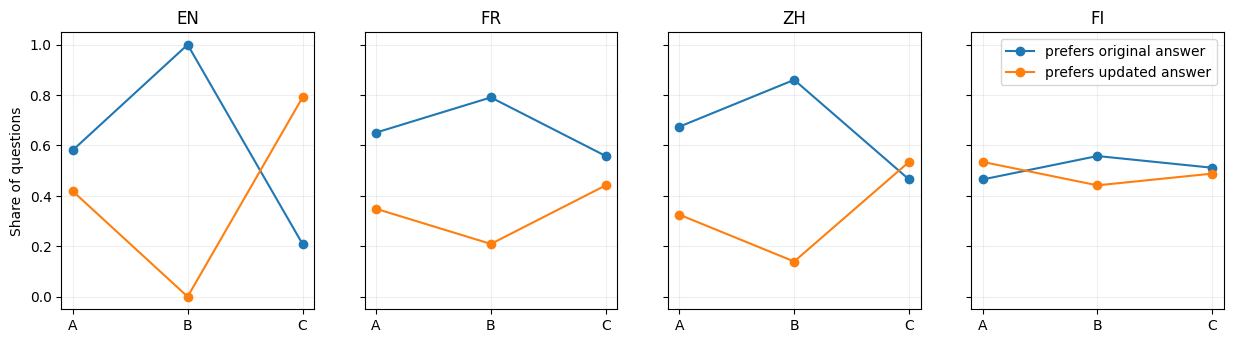

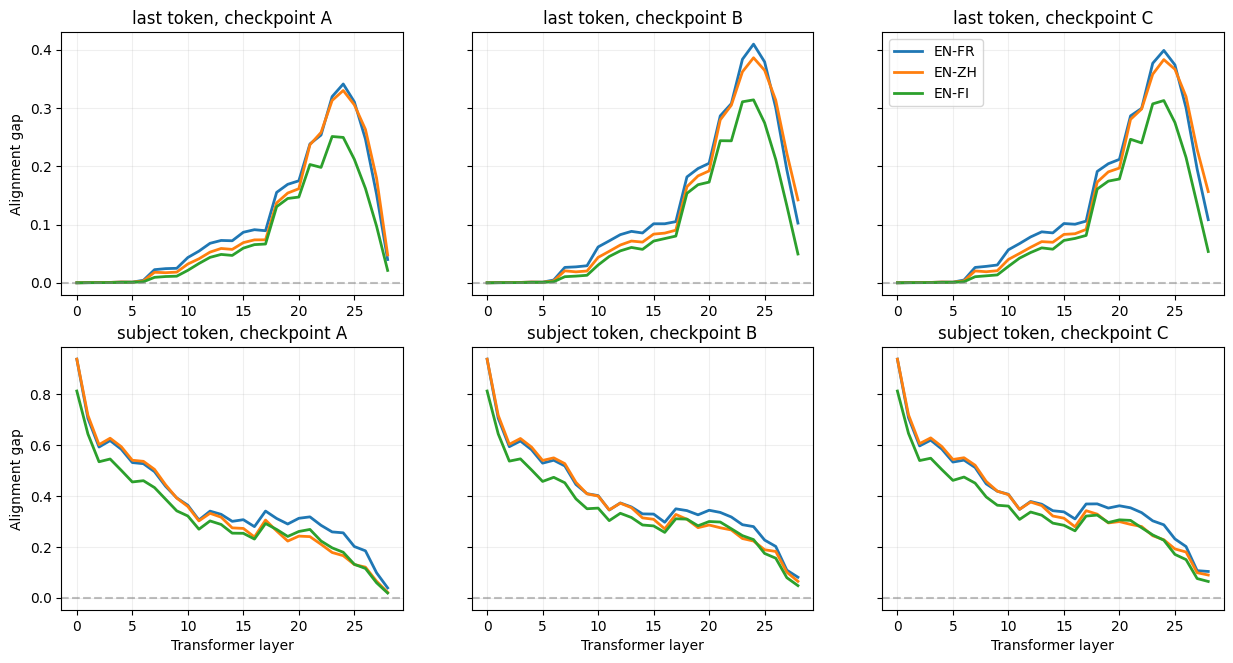

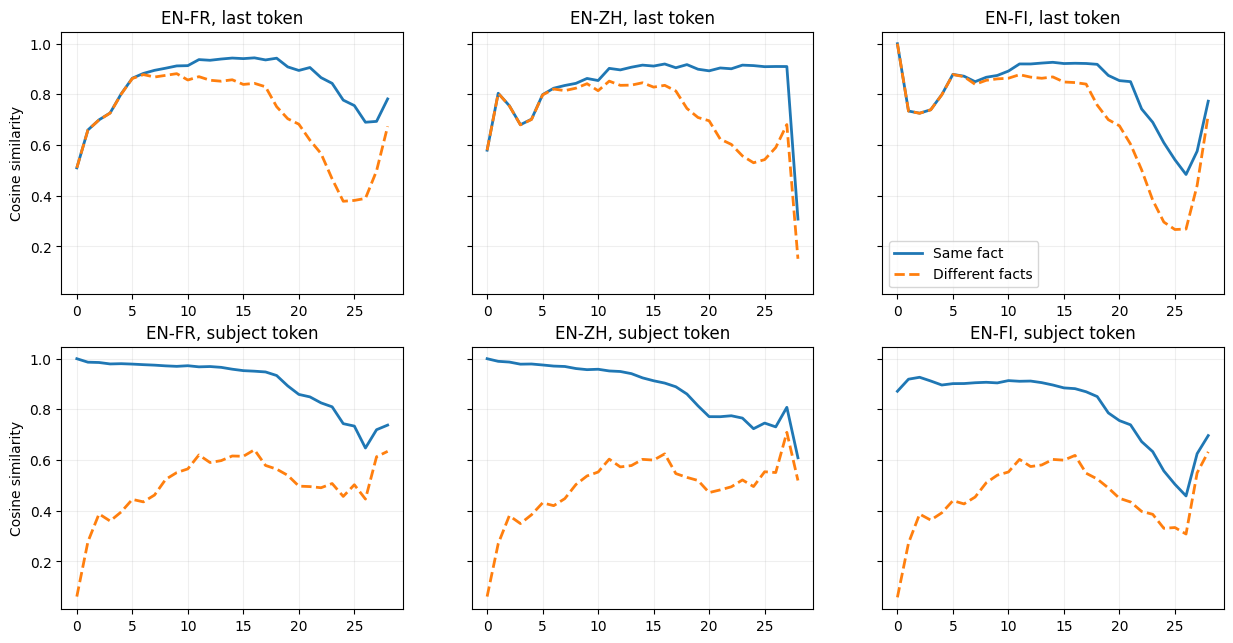

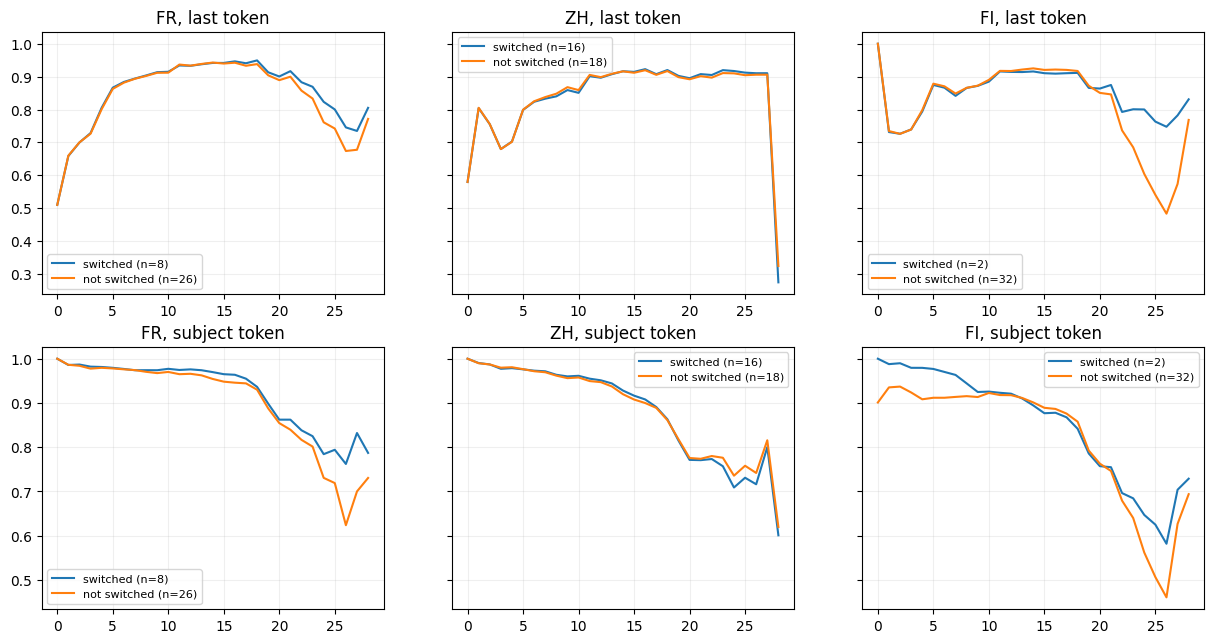

Results saved to: /content/drive/MyDrive/64610/results/alignment_fewshot
['alignment_by_transfer_outcome.csv', 'alignment_by_transfer_outcome_fewshot.png', 'checkpoint_preference_accuracy.csv', 'checkpoint_preference_accuracy_summary.csv', 'conditional_transfer_strict_and_pilot.csv', 'layerwise_alignment_gap.csv', 'layerwise_alignment_per_fact.csv', 'layerwise_alignment_summary.csv', 'paper_alignment_gap_fewshot.pdf', 'paper_preference_stages_fewshot.pdf', 'paper_similarity_components_fewshot.pdf']


In [13]:
def save(fig, name):
    fig.savefig(os.path.join(RESULTS_DIR, name), bbox_inches='tight', dpi=180)
    plt.show()

# 1. Old vs new preference at each checkpoint (replaces the accuracy bar chart)
langs = ['en', 'fr', 'zh', 'fi']
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, lang in zip(axes, langs):
    d = accuracy_summary[accuracy_summary.language == lang].set_index('checkpoint').loc[['A', 'B', 'C']]
    ax.plot(d.index, 1 - d.prefers_new, marker='o', label='prefers original answer')
    ax.plot(d.index, d.prefers_new, marker='o', label='prefers updated answer')
    ax.set_title(lang.upper()); ax.set_ylim(-0.05, 1.05); ax.grid(alpha=0.2)
axes[0].set_ylabel('Share of questions'); axes[-1].legend()
save(fig, 'paper_preference_stages_fewshot.pdf')

# 2. Alignment gap per checkpoint, one row per position
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey='row')
for r, pos in enumerate(POSITIONS):
    for ax, ckpt in zip(axes[r], ['A', 'B', 'C']):
        for lang in ['fr', 'zh', 'fi']:
            d = gap_df[(gap_df.position == pos) & (gap_df.checkpoint == ckpt) & (gap_df.language == lang)]
            ax.plot(d.layer, d.A_gap, label=f'EN-{lang.upper()}', linewidth=2)
        ax.set_title(f'{pos} token, checkpoint {ckpt}'); ax.axhline(0, color='gray', linestyle='--', alpha=0.5); ax.grid(alpha=0.2)
    axes[r][0].set_ylabel('Alignment gap')
axes[0][-1].legend()
for ax in axes[-1]: ax.set_xlabel('Transformer layer')
save(fig, 'paper_alignment_gap_fewshot.pdf')

# 3. Same-fact vs different-fact similarity at checkpoint C
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey=True)
for r, pos in enumerate(POSITIONS):
    for ax, lang in zip(axes[r], ['fr', 'zh', 'fi']):
        d = gap_df[(gap_df.position == pos) & (gap_df.checkpoint == 'C') & (gap_df.language == lang)]
        ax.plot(d.layer, d.S_same, label='Same fact', linewidth=2)
        ax.plot(d.layer, d.S_different, label='Different facts', linewidth=2, linestyle='--')
        ax.set_title(f'EN-{lang.upper()}, {pos} token'); ax.grid(alpha=0.2)
    axes[r][0].set_ylabel('Cosine similarity')
axes[0][-1].legend()
save(fig, 'paper_similarity_components_fewshot.pdf')

# 4. Same-fact EN-target cosine at C: strict switches vs not (exploratory, small n)
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharey='row')
for r, pos in enumerate(POSITIONS):
    for ax, lang in zip(axes[r], ['fr', 'zh', 'fi']):
        d = comparison[(comparison.position == pos) & (comparison.language == lang)]
        for ok, label in [(True, 'switched'), (False, 'not switched')]:
            s = d[d.local_switched == ok]
            if len(s):
                ax.plot(s.layer, s.mean_cosine, label=f'{label} (n={int(s.n.iloc[0])})')
        ax.set_title(f'{lang.upper()}, {pos} token'); ax.legend(fontsize=8); ax.grid(alpha=0.2)
save(fig, 'alignment_by_transfer_outcome_fewshot.png')
print('Results saved to:', RESULTS_DIR)
print(sorted(os.listdir(RESULTS_DIR)))